<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Historical Sales Dataset:
    Month  Advertising  Sales
0       1           10    100
1       2           12    110
2       3           11    108
3       4           13    120
4       5           15    130
5       6           14    125
6       7           16    140
7       8           18    150
8       9           17    145
9      10           19    160
10     11           20    170
11     12           22    180
12     13           21    175
13     14           23    190
14     15           24    200
15     16           25    205
16     17           26    215
17     18           28    225
18     19           27    220
19     20           29    235
20     21           30    245
21     22           32    255
22     23           31    250
23     24           34    270

Future Sales Prediction Results
--------------------------------
Mean Absolute Error: 1.92
Mean Squared Error: 5.47
Root Mean Squared Error: 2.34
R2 Score: 0.9777

Actual vs Predicted Sales:
   Month  Actual Sales  Predicte

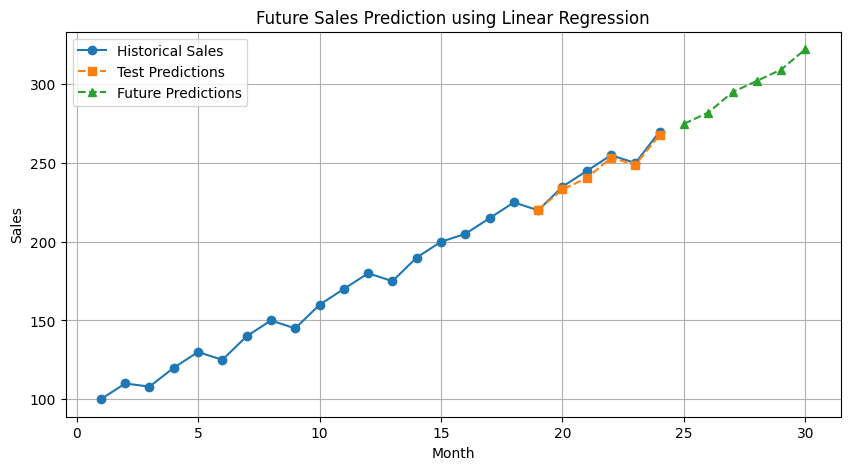


Files saved successfully:
1. sales_test_predictions.csv
2. future_sales_predictions.csv


In [1]:

# Future Sales Prediction using Linear Regression

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 2: Create historical sales dataset
data = {
    "Month": list(range(1, 25)),
    "Advertising": [
        10, 12, 11, 13, 15, 14,
        16, 18, 17, 19, 20, 22,
        21, 23, 24, 25, 26, 28,
        27, 29, 30, 32, 31, 34
    ],
    "Sales": [
        100, 110, 108, 120, 130, 125,
        140, 150, 145, 160, 170, 180,
        175, 190, 200, 205, 215, 225,
        220, 235, 245, 255, 250, 270
    ]
}

df = pd.DataFrame(data)

print("Historical Sales Dataset:")
print(df)

# Step 3: Separate input features and target variable
X = df[["Month", "Advertising"]]
y = df["Sales"]

# Step 4: Split data chronologically
# First 18 months for training, last 6 months for testing
X_train = X.iloc[:18]
X_test = X.iloc[18:]

y_train = y.iloc[:18]
y_test = y.iloc[18:]

# Step 5: Create and train Linear Regression model
model = LinearRegression()

model.fit(X_train, y_train)

# Step 6: Predict sales on test data
y_pred = model.predict(X_test)

# Step 7: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nFuture Sales Prediction Results")
print("--------------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 8: Compare actual and predicted sales
results = pd.DataFrame({
    "Month": X_test["Month"].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": np.round(y_pred, 2)
})

print("\nActual vs Predicted Sales:")
print(results)

# Step 9: Predict future sales for next 6 months
future_data = pd.DataFrame({
    "Month": [25, 26, 27, 28, 29, 30],
    "Advertising": [35, 36, 38, 39, 40, 42]
})

future_predictions = model.predict(future_data)

future_results = pd.DataFrame({
    "Month": future_data["Month"],
    "Advertising": future_data["Advertising"],
    "Predicted Sales": np.round(future_predictions, 2)
})

print("\nFuture Sales Prediction:")
print(future_results)

# Step 10: Visualize actual and predicted sales
plt.figure(figsize=(10, 5))

plt.plot(
    df["Month"],
    df["Sales"],
    marker="o",
    label="Historical Sales"
)

plt.plot(
    X_test["Month"],
    y_pred,
    marker="s",
    linestyle="--",
    label="Test Predictions"
)

plt.plot(
    future_data["Month"],
    future_predictions,
    marker="^",
    linestyle="--",
    label="Future Predictions"
)

plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Future Sales Prediction using Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

# Step 11: Save results to CSV
results.to_csv("sales_test_predictions.csv", index=False)

future_results.to_csv("future_sales_predictions.csv", index=False)

print("\nFiles saved successfully:")
print("1. sales_test_predictions.csv")
print("2. future_sales_predictions.csv")
